Analyzing event: OGLE-2024-blg-0010
Data source: https://www.astrouw.edu.pl/ogle/ogle4/ews/2024/blg-0010/phot.dat
Estimated baseline flux: 0.9824949504638227

========== BOOTSTRAP RESULTS ==========
Requested samples: 10000
Valid samples: 9991
Rejected samples: 9

t0 = 2460383.536090 +/- 0.121420 HJD
u0 = 0.500351 +/- 0.002129
tE = 11.795735 +/- 0.495633 days

Original reduced chi-square = 0.9137

========== COMPARISON WITH OGLE ==========

t0 (HJD)
Bootstrap: 2460383.536090 +/- 0.121420
OGLE:      2460383.444000 +/- 0.055000
Difference (Bootstrap - OGLE): +0.092090
Combined uncertainty: 0.133296
N_sigma (absolute): 0.691
Signed difference / combined sigma: +0.691

u0
Bootstrap: 0.500351 +/- 0.002129
OGLE:      0.506000 +/- 0.003000
Difference (Bootstrap - OGLE): -0.005649
Combined uncertainty: 0.003679
N_sigma (absolute): 1.536
Signed difference / combined sigma: -1.536

tE (days)
Bootstrap: 11.795735 +/- 0.495633
OGLE:      9.854000 +/- 0.113000
Difference (Bootstrap - OGLE): +1.9417

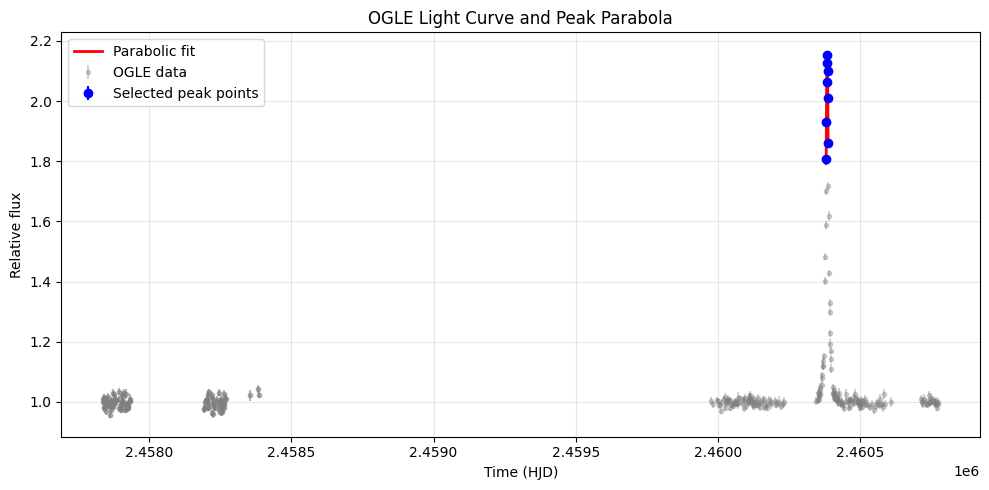

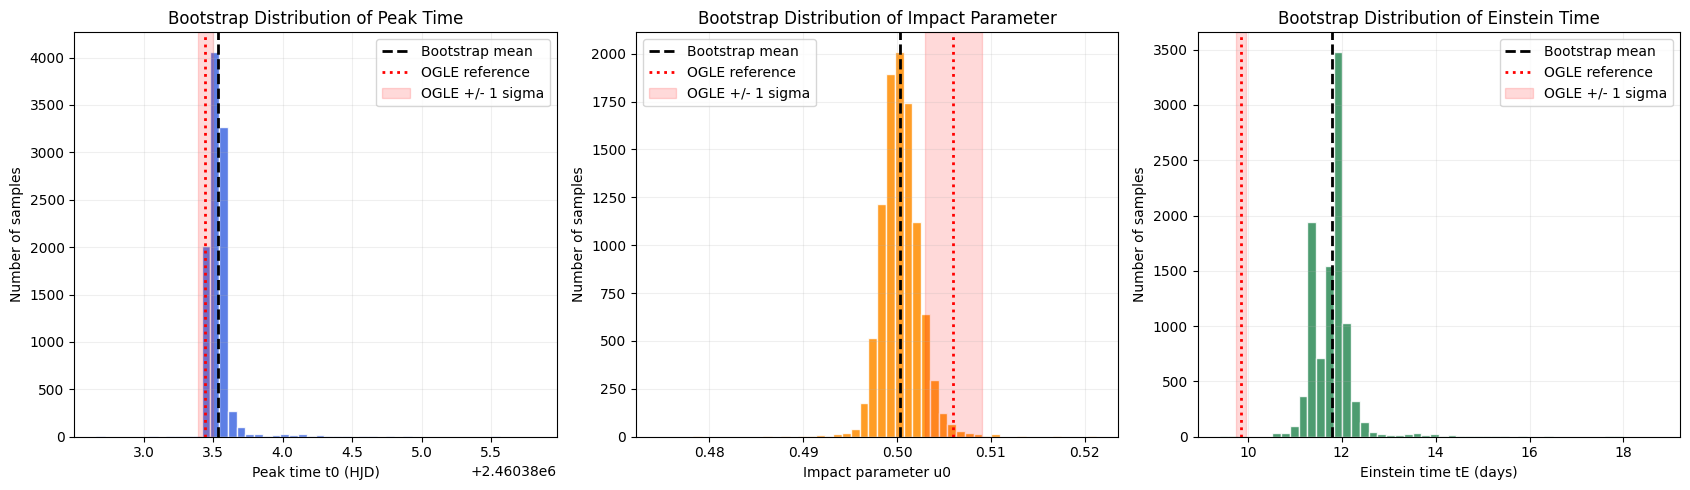

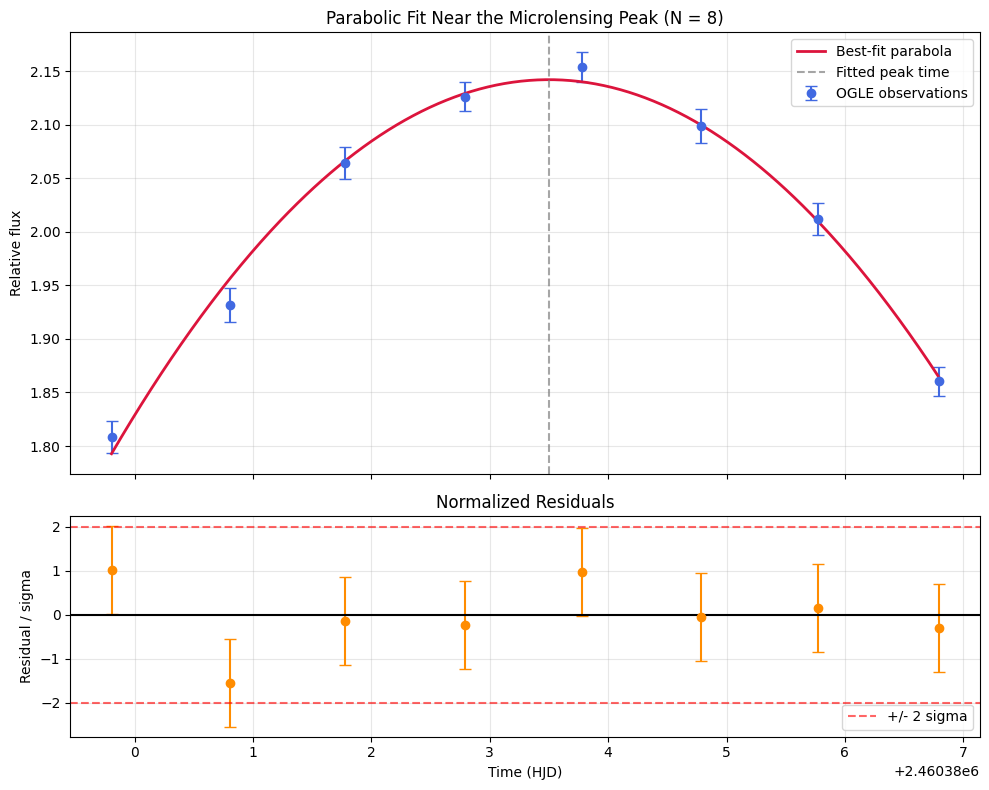


========== RESIDUAL ANALYSIS ==========
Number of observations: 8
Degrees of freedom: 5
Reduced chi-square: 0.9137

Normalized residuals:
Time = 2460379.80482, Residual = +1.016 sigma
Time = 2460380.80745, Residual = -1.545 sigma
Time = 2460381.77884, Residual = -0.132 sigma
Time = 2460382.79145, Residual = -0.233 sigma
Time = 2460383.77766, Residual = +0.977 sigma
Time = 2460384.78483, Residual = -0.060 sigma
Time = 2460385.77482, Residual = +0.154 sigma
Time = 2460386.79159, Residual = -0.310 sigma

========== FINAL RESULTS TABLE ==========
Parameter  Bootstrap mean  Bootstrap std  OGLE reference  OGLE uncertainty  Difference  Combined uncertainty  N_sigma  Signed sigma
 t0 (HJD)  2460383.536090       0.121420  2460383.444000          0.055000    0.092090              0.133296 0.690868      0.690868
       u0        0.500351       0.002129        0.506000          0.003000   -0.005649              0.003679 1.535576     -1.535576
tE (days)       11.795735       0.495633        9.8540

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from io import StringIO
from urllib.request import urlopen
import re
# ============================================================
# PART A - GRAVITATIONAL MICROLENSING BOOTSTRAP ANALYSIS
# ============================================================

# ---------------- USER SETTINGS ----------------

OGLE_URL = "https://www.astrouw.edu.pl/ogle/ogle4/ews/2024/blg-0010/phot.dat"

# Extract event year and ID from the OGLE URL
match = re.search(r"/ews/(\d{4})/(blg-\d+)/", OGLE_URL)

if match:
    EVENT_YEAR = match.group(1)
    EVENT_ID = match.group(2)
    EVENT_NAME = f"OGLE-{EVENT_YEAR}-{EVENT_ID}"
else:
    EVENT_NAME = "Unknown OGLE event"

print("=" * 50)
print(f"Analyzing event: {EVENT_NAME}")
print(f"Data source: {OGLE_URL}")
print("=" * 50)


# Number of observations used near the peak
N_PEAK_POINTS =8

# Number of bootstrap samples
N_BOOTSTRAP = 10000

# Blending fraction: 1 means no blending
F_S = 1

# OGLE reference parameters (fill these in)
OGLE_T0 = 2460383.444      # Peak time (HJD)
OGLE_U0 = 0.506	       # Minimum impact parameter
OGLE_TE = 9.854				       # Einstein time (days)

# REQUIRED: enter OGLE published 1-sigma uncertainties (not percentages)
OGLE_T0_ERR = 0.055  # HJD
OGLE_U0_ERR = 0.003  # dimensionless
OGLE_TE_ERR = 0.113 # days

RANDOM_SEED = 42

# ---------------- PHYSICAL MODEL ----------------

def amplification(u):
    return (u**2 + 2) / (u * np.sqrt(u**2 + 4))

def amplification_derivative(u):
    return -8 / (u**2 * (u**2 + 4)**1.5)

def find_u0(A_peak):
    if A_peak <= 1:
        return np.nan

    return brentq(
        lambda u: amplification(u) - A_peak,
        1e-8, 1e6
    )

# ---------------- LOAD OGLE DATA ----------------

if "PASTE_" in OGLE_URL:
    raise ValueError("Please insert the OGLE phot.dat URL.")

with urlopen(OGLE_URL, timeout=30) as response:
    raw_text = response.read().decode("utf-8")

data = pd.read_csv(
    StringIO(raw_text),
    sep=r"\s+",
    comment="#",
    header=None
)

# Standard OGLE phot.dat:
# column 0: HJD
# column 1: magnitude
# column 2: magnitude uncertainty

time = pd.to_numeric(data.iloc[:, 0], errors="coerce").to_numpy()
mag = pd.to_numeric(data.iloc[:, 1], errors="coerce").to_numpy()
mag_err = pd.to_numeric(data.iloc[:, 2], errors="coerce").to_numpy()

valid = (
    np.isfinite(time) &
    np.isfinite(mag) &
    np.isfinite(mag_err) &
    (mag_err > 0)
)

time = time[valid]
mag = mag[valid]
mag_err = mag_err[valid]

order = np.argsort(time)
time = time[order]
mag = mag[order]
mag_err = mag_err[order]

if len(time) < N_PEAK_POINTS:
    raise ValueError("Not enough valid OGLE observations.")

# Relative flux, with an arbitrary common normalization
flux = 10**(-0.4 * (mag - np.median(mag)))

# Error propagation: magnitude -> flux
flux_err = (np.log(10) / 2.5) * flux * mag_err

# ---------------- BASELINE FLUX ----------------

# Estimate baseline using the faintest 30% in flux.
# This assumes that these observations are mostly unmagnified.

baseline_mask = flux <= np.quantile(flux, 0.30)

weights = 1 / flux_err[baseline_mask]**2

F_BASE = np.sum(weights * flux[baseline_mask]) / np.sum(weights)

print("Estimated baseline flux:", F_BASE)

# ---------------- SELECT PEAK POINTS ----------------

peak_index = np.argmax(flux)
peak_time_guess = time[peak_index]

selected = np.argsort(
    np.abs(time - peak_time_guess)
)[:N_PEAK_POINTS]

selected = selected[np.argsort(time[selected])]

t_peak = time[selected]
f_peak = flux[selected]
df_peak = flux_err[selected]

T_REF = peak_time_guess
x_peak = t_peak - T_REF

# ---------------- PARABOLIC CHI-SQUARE FIT ----------------

def fit_parabola(x, y, sigma):
    """
    Weighted least squares:
        F(x) = a + b*x + c*x^2
    """

    X = np.column_stack([
        np.ones(len(x)),
        x,
        x**2
    ])

    X_weighted = X / sigma[:, None]
    y_weighted = y / sigma

    if np.linalg.matrix_rank(X_weighted) < 3:
        return None

    coefficients = np.linalg.lstsq(
        X_weighted, y_weighted, rcond=None
    )[0]

    a, b, c = coefficients

    model = X @ coefficients

    chi2 = np.sum(((y - model) / sigma)**2)
    dof = len(x) - 3

    chi2_red = chi2 / dof if dof > 0 else np.nan

    return a, b, c, chi2_red

# ---------------- PHYSICAL PARAMETERS ----------------

def physical_parameters(a, b, c):
    """
    Convert local parabola coefficients into:
        t0 - peak time
        u0 - minimum impact parameter
        tE - Einstein time
    """

    if c >= 0:
        return None

    # Vertex of the parabola
    x0 = -b / (2 * c)
    t0 = T_REF + x0

    F_max = a - b**2 / (4 * c)

    # Observed amplification including blending
    A_peak = 1 + (F_max / F_BASE - 1) / F_S

    if A_peak <= 1:
        return None

    u0 = find_u0(A_peak)

    # Second-order expansion of the microlensing model:
    # c = F_BASE * F_S * A'(u0) / (2*u0*tE^2)

    ratio = (
        F_BASE * F_S * amplification_derivative(u0)
        / (2 * u0 * c)
    )

    if ratio <= 0 or not np.isfinite(ratio):
        return None

    tE = np.sqrt(ratio)

    if not np.all(np.isfinite([t0, u0, tE])):
        return None

    return t0, u0, tE

# ---------------- ORIGINAL FIT ----------------

original_fit = fit_parabola(
    x_peak, f_peak, df_peak
)

if original_fit is None:
    raise ValueError("Original parabola fit failed.")

a, b, c, chi2_red = original_fit

original_physics = physical_parameters(a, b, c)

if original_physics is None:
    raise ValueError(
        "Original fit is not physically valid. "
        "Try a different peak window."
    )

# ---------------- BOOTSTRAP ----------------

rng = np.random.default_rng(RANDOM_SEED)

bootstrap_results = []
bootstrap_chi2 = []

for i in range(N_BOOTSTRAP):

    # Resample observations WITH replacement
    indices = rng.integers(
        0, N_PEAK_POINTS, N_PEAK_POINTS
    )

    x_sample = x_peak[indices]
    y_sample = f_peak[indices]
    sigma_sample = df_peak[indices]

    fit = fit_parabola(
        x_sample, y_sample, sigma_sample
    )

    if fit is None:
        continue

    a_i, b_i, c_i, chi2_i = fit

    physics = physical_parameters(a_i, b_i, c_i)

    if physics is None:
        continue

    t0_i, u0_i, tE_i = physics

    # Require fitted peak to lie inside the selected window
    if not (t_peak.min() <= t0_i <= t_peak.max()):
        continue

    bootstrap_results.append([t0_i, u0_i, tE_i])
    bootstrap_chi2.append(chi2_i)

bootstrap_results = np.array(bootstrap_results)

if len(bootstrap_results) < 2:
    raise ValueError(
        "Too few valid bootstrap fits. "
        "Check the peak selection and blending."
    )

# ---------------- STATISTICS ----------------

means = np.mean(bootstrap_results, axis=0)

stds = np.std(
    bootstrap_results,
    axis=0,
    ddof=1
)

t0_mean, u0_mean, tE_mean = means
t0_std, u0_std, tE_std = stds

print("\n========== BOOTSTRAP RESULTS ==========")

print(f"Requested samples: {N_BOOTSTRAP}")
print(f"Valid samples: {len(bootstrap_results)}")
print(f"Rejected samples: {N_BOOTSTRAP - len(bootstrap_results)}")

print(f"\nt0 = {t0_mean:.6f} +/- {t0_std:.6f} HJD")
print(f"u0 = {u0_mean:.6f} +/- {u0_std:.6f}")
print(f"tE = {tE_mean:.6f} +/- {tE_std:.6f} days")

print(f"\nOriginal reduced chi-square = {chi2_red:.4f}")

# ---------------- OGLE COMPARISON ----------------

# All three OGLE 1-sigma errors are required for N_sigma.
ogle_values = np.array([OGLE_T0, OGLE_U0, OGLE_TE], dtype=float)
ogle_errors_input = [OGLE_T0_ERR, OGLE_U0_ERR, OGLE_TE_ERR]
names = ["t0 (HJD)", "u0", "tE (days)"]

missing = [name for name, err in zip(names, ogle_errors_input) if err is None]
if missing:
    raise ValueError(
        "Enter OGLE 1-sigma errors at the top of the notebook for: "
        + ", ".join(missing)
        + ". The N_sigma comparison cannot be calculated without them."
    )

ogle_errors = np.array(ogle_errors_input, dtype=float)
if np.any(~np.isfinite(ogle_values)) or np.any(~np.isfinite(ogle_errors)) or np.any(ogle_errors < 0):
    raise ValueError("OGLE values/errors must be finite and uncertainties nonnegative.")

# Bootstrap means and standard deviations were computed above.
differences = means - ogle_values
combined_errors = np.sqrt(stds**2 + ogle_errors**2)
if np.any(combined_errors <= 0):
    raise ValueError("Combined uncertainties must be positive.")

# Absolute N_sigma for agreement; signed difference for direction.
N_sigma = np.abs(differences) / combined_errors
signed_sigma = differences / combined_errors

print("\n========== COMPARISON WITH OGLE ==========")
for j, name in enumerate(names):
    print(f"\n{name}")
    print(f"Bootstrap: {means[j]:.6f} +/- {stds[j]:.6f}")
    print(f"OGLE:      {ogle_values[j]:.6f} +/- {ogle_errors[j]:.6f}")
    print(f"Difference (Bootstrap - OGLE): {differences[j]:+.6f}")
    print(f"Combined uncertainty: {combined_errors[j]:.6f}")
    print(f"N_sigma (absolute): {N_sigma[j]:.3f}")
    print(f"Signed difference / combined sigma: {signed_sigma[j]:+.3f}")

# Note: quadrature assumes independent estimates. OGLE and bootstrap
# use observations from the same event, so this is an approximate comparison.

# ---------------- LIGHT CURVE ----------------

x_plot = np.linspace(
    x_peak.min(),
    x_peak.max(),
    400
)

f_plot = a + b*x_plot + c*x_plot**2

plt.figure(figsize=(10, 5))

plt.errorbar(
    time, flux, yerr=flux_err,
    fmt=".", color="gray", alpha=0.35,
    label="OGLE data"
)

plt.errorbar(
    t_peak, f_peak, yerr=df_peak,
    fmt="o", color="blue",
    label="Selected peak points"
)

plt.plot(
    T_REF + x_plot, f_plot,
    color="red", linewidth=2,
    label="Parabolic fit"
)

plt.xlabel("Time (HJD)")
plt.ylabel("Relative flux")
plt.title("OGLE Light Curve and Peak Parabola")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("light_curve.pdf", bbox_inches="tight")
plt.show()

# ---------------- HISTOGRAMS ----------------

colors = ["royalblue", "darkorange", "seagreen"]

labels = [
    "Peak time t0 (HJD)",
    "Impact parameter u0",
    "Einstein time tE (days)"
]

titles = [
    "Bootstrap Distribution of Peak Time",
    "Bootstrap Distribution of Impact Parameter",
    "Bootstrap Distribution of Einstein Time"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for j, ax in enumerate(axes):

    values = bootstrap_results[:, j]

    ax.hist(
        values,
        bins=50,
        color=colors[j],
        edgecolor="white",
        alpha=0.85
    )

    ax.axvline(
        means[j],
        color="black",
        linestyle="--",
        linewidth=2,
        label="Bootstrap mean"
    )

    if ogle_values[j] is not None:
        ax.axvline(
            ogle_values[j],
            color="red",
            linestyle=":",
            linewidth=2,
            label="OGLE reference"
        )
        if ogle_errors[j] is not None:
            if not np.isfinite(ogle_errors[j]) or ogle_errors[j] < 0:
                raise ValueError(f"Invalid OGLE uncertainty for {names[j]}")
            ax.axvspan(
                ogle_values[j] - ogle_errors[j],
                ogle_values[j] + ogle_errors[j],
                color="red", alpha=0.15,
                label="OGLE +/- 1 sigma"
            )

    ax.set_title(titles[j])
    ax.set_xlabel(labels[j])
    ax.set_ylabel("Number of samples")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.savefig("bootstrap_histograms.pdf", bbox_inches="tight")
plt.show()


# ============================================================
# PEAK ZOOM-IN AND RESIDUALS
# ============================================================

# Parabolic fit from the original observations
# F(t) = a + b*(t - T_REF) + c*(t - T_REF)^2

t_fit = np.linspace(t_peak.min(), t_peak.max(), 500)
x_fit = t_fit - T_REF

F_fit = a + b*x_fit + c*x_fit**2

# Model predictions at the selected observations
F_model = a + b*x_peak + c*x_peak**2

# Raw and normalized residuals
residuals = f_peak - F_model
normalized_residuals = residuals / df_peak

# Create two vertically aligned plots
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# ------------------------------------------------------------
# PLOT 1: ZOOM-IN ON THE PARABOLIC FIT
# ------------------------------------------------------------

ax1.errorbar(
    t_peak,
    f_peak,
    yerr=df_peak,
    fmt="o",
    color="royalblue",
    capsize=4,
    markersize=6,
    label="OGLE observations"
)

ax1.plot(
    t_fit,
    F_fit,
    color="crimson",
    linewidth=2,
    label="Best-fit parabola"
)

ax1.axvline(
    original_physics[0],
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Fitted peak time"
)

ax1.set_ylabel("Relative flux")
ax1.set_title(
    f"Parabolic Fit Near the Microlensing Peak "
    f"(N = {len(t_peak)})"
)

ax1.legend()
ax1.grid(alpha=0.3)

#ax1.text(
 #   0.03, 0.05,
  #  f"Reduced chi-square = {chi2_red:.3f}",
   # transform=ax1.transAxes,
    #fontsize=11,
    #bbox=dict(facecolor="white", alpha=0.8)
#)

# ------------------------------------------------------------
# PLOT 2: NORMALIZED RESIDUALS
# ------------------------------------------------------------

ax2.errorbar(
    t_peak,
    normalized_residuals,
    yerr=np.ones_like(normalized_residuals),
    fmt="o",
    color="darkorange",
    capsize=4,
    markersize=6
)

ax2.axhline(
    0,
    color="black",
    linewidth=1.5
)

ax2.axhline(
    2,
    color="red",
    linestyle="--",
    alpha=0.6,
    label="+/- 2 sigma"
)

ax2.axhline(
    -2,
    color="red",
    linestyle="--",
    alpha=0.6
)

ax2.set_xlabel("Time (HJD)")
ax2.set_ylabel("Residual / sigma")
ax2.set_title("Normalized Residuals")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()

# Save figure for Overleaf
plt.savefig(
    "parabolic_fit_and_residuals.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# NUMERICAL RESIDUALS
# ------------------------------------------------------------

print("\n========== RESIDUAL ANALYSIS ==========")

print(f"Number of observations: {len(t_peak)}")
print(f"Degrees of freedom: {len(t_peak) - 3}")
print(f"Reduced chi-square: {chi2_red:.4f}")

print("\nNormalized residuals:")

for t, r in zip(t_peak, normalized_residuals):
    print(f"Time = {t:.5f}, Residual = {r:+.3f} sigma")


# ---------------- RESULTS TABLE ----------------

results_table = pd.DataFrame({
    "Parameter": names,
    "Bootstrap mean": means,
    "Bootstrap std": stds,
    "OGLE reference": ogle_values,
    "OGLE uncertainty": ogle_errors,
    "Difference": differences,
    "Combined uncertainty": combined_errors,
    "N_sigma": N_sigma,
    "Signed sigma": signed_sigma,
})

print("\n========== FINAL RESULTS TABLE ==========")
print(results_table.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

